# 03. A0 기본 CNN (기준점) · 5 fold × 3 seed
**9week** · 계획서: [연구계획서.md](연구계획서.md) · 데이터·분할: [02](02_정제_분할_A0_흐름확인.ipynb)

**이 문서의 역할:** 모든 비교의 기준점인 A0를 5 fold × 3 seed로 학습한다. A1·A2·B 계열은 모두 이 결과와 같은 fold끼리 비교한다.

| 항목 | 내용 |
|---|---|
| 구조 | stem Conv → [Conv→BN→ReLU→Conv→BN]→ReLU→MaxPool × 2 → GAP → Dropout → Dense(6) |
| 비교 대상 | 없음 (기준점) |
| 기록 | fold·seed별 Accuracy, Macro F1, 행동별 recall, 최고 epoch, 학습시간, 파라미터 수, 사람별 정확도 |

**실행 방법 (Colab)**
1. 런타임 → 런타임 유형 변경 → **GPU**
2. 위에서부터 모든 셀 실행. 첫 셀에서 Google Drive 연결을 허락한다.
3. 결과 표는 노트북 출력에 남고, 같은 내용이 `9week/runs/` 폴더에 CSV로 저장된다. 이 CSV는 다른 모델과 같은 fold끼리 비교하기 위해 사용한다.

**실행 전 점검 (2026-11-16):** Colab GPU에서 실행합니다. 완료한 fold/seed는 `runs/*_progress.json`에 저장되어 재실행 시 건너뜁니다. 중단된 실행 1회는 다시 학습합니다. 각 실행의 학습 곡선, 검증 예측, 표준화 값, 최적 가중치를 저장합니다. 요약·비교는 15회 완료 후에만 가능합니다. 학습 코드나 구조를 변경한 경우 이전 결과를 별도 보관하고 새 실험으로 시작하세요. 검증 Macro F1은 조기 종료에도 사용하는 개발 지표이며 최종 성능은 보류한 테스트에서 확인합니다.


## 1. 설정
- 데이터, 분할, 학습 설정은 **모든 모델 노트북에서 같다.** 바뀌는 것은 `MODEL_NAME`과 3절의 모델 코드뿐이다.
- 분할 ID는 02에서 확정한 값을 그대로 복사했다.

In [ ]:
import os, re, sys, tarfile, time, json, hashlib, platform
import numpy as np
import pandas as pd
from collections import Counter

if 'google.colab' in sys.modules:                       # Colab: Google Drive 연결
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/가천대학교/2026-2/1. 기계학습프로그래밍'
else:                                                   # PC에서 실행할 때
    BASE = r'D:\가천대학교\26-2\1. 기계학습프로그래밍'
ARCHIVE = os.path.join(BASE, 'DATA', 'WISDM', 'WISDM_ar_latest.tar.gz')
RUN_DIR = os.path.join(BASE, '9week', 'runs')
os.makedirs(RUN_DIR, exist_ok=True)

MODEL_NAME = 'A0'
SEEDS = [0, 1, 2]
FOLDS = [0, 1, 2, 3, 4]

ACTIVITIES = ['Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']
WIN, TRAIN_STRIDE, EVAL_STRIDE = 128, 64, 128
MAX_GAP_NS = 1_000_000_000

TEST_USERS = [6, 21, 24, 27, 29, 34]                    # 최종 평가 전까지 사용하지 않음
GROUPS = [[1, 7, 20, 22, 25, 36],
          [9, 16, 19, 26, 28, 33],
          [2, 3, 4, 14, 30, 31],
          [8, 10, 11, 12, 13, 15],
          [5, 17, 18, 23, 32, 35]]
assert os.path.isfile(ARCHIVE), f'데이터 파일이 없습니다: {ARCHIVE}'
all_users = [u for group in GROUPS for u in group]
assert len(all_users) == len(set(all_users)) == 30
assert not set(all_users) & set(TEST_USERS)
assert set(all_users + TEST_USERS) == set(range(1, 37))
assert set(FOLDS) <= set(range(5)) and set(SEEDS) <= {0, 1, 2}


Dataset SHA-256 verified


## 2. 데이터 읽기와 정제 (02와 같은 규칙)
timestamp 0 삭제 → 완전 중복 삭제 → 같은 시각의 두 번째 값 삭제 → 사용자·행동 변경, 시간 역행, 1초 초과 공백에서 구간 끊기 → 128 이상 구간만 사용. 마지막 줄에 02와 같은 수(구간 424개, 윈도우 7,841개)가 나와야 한다.

In [ ]:
with tarfile.open(ARCHIVE) as tar:
    raw = tar.extractfile('WISDM_ar_v1.1/WISDM_ar_v1.1_raw.txt').read().decode()

records = []
for token in re.split(r'[;\r\n]+', raw):
    token = token.strip()
    if token == '':
        continue
    fields = token.split(',')
    if len(fields) == 7 and fields[-1].strip() == '':
        fields = fields[:6]
    try:
        if len(fields) != 6:
            raise ValueError
        records.append((int(fields[0]), ACTIVITIES.index(fields[1]), int(fields[2]),
                        float(fields[3]), float(fields[4]), float(fields[5])))
    except ValueError:
        records.append(None)

seen, kept = set(), []
for r in records:
    if r is None:
        kept.append(None)
        continue
    if r[2] == 0 or r in seen:
        continue
    seen.add(r)
    last = kept[-1] if kept else None
    if last is not None and last[:2] == r[:2] and last[2] == r[2]:
        continue
    kept.append(r)

usable, start = [], 0
for i in range(1, len(kept) + 1):
    a = kept[i - 1]
    b = kept[i] if i < len(kept) else None
    if not (a is not None and b is not None and a[:2] == b[:2] and 0 < b[2] - a[2] <= MAX_GAP_NS):
        part = [r for r in kept[start:i] if r is not None]
        if len(part) >= WIN:
            usable.append((part[0][0], part[0][1], np.array([r[3:] for r in part], dtype=np.float32)))
        start = i

print('128 이상 구간:', len(usable), '/ 윈도우(stride 128):',
      sum((len(x) - WIN) // EVAL_STRIDE + 1 for u, a, x in usable))

128 이상 구간: 424 / 윈도우(stride 128): 7841


In [ ]:
def make_windows(users, stride, mean, std):
    X, y, who = [], [], []
    for u, a, x in usable:
        if u not in users:
            continue
        x = (x - mean) / std
        for s in range(0, len(x) - WIN + 1, stride):
            X.append(x[s:s + WIN])
            y.append(a)
            who.append(u)
    return np.array(X, dtype=np.float32), np.array(y), np.array(who)

## 3. 모델
다른 모델 노트북은 이 셀과 6절의 비교 대상만 다르다.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import f1_score, recall_score

gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus)
if 'google.colab' in sys.modules and not gpus:
    raise RuntimeError('런타임 유형을 GPU로 변경한 뒤 다시 실행하세요.')

# A0: 기본 CNN. A1에서는 '# A1에서는' 줄만 바뀐다
def conv_bn(x, filters, relu=True):
    x = layers.Conv1D(filters, 5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x) if relu else x

def build_model():
    inputs = layers.Input(shape=(WIN, 3))
    x = conv_bn(inputs, 64)                     # stem
    for block in range(2):
        h = conv_bn(x, 64)
        h = conv_bn(h, 64, relu=False)
        x = layers.ReLU()(h)                    # A1에서는 ReLU(h + x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(6, activation='softmax')(x)
    return models.Model(inputs, outputs, name=MODEL_NAME)

build_model().summary()

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Model: "A0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 128, 64)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 128, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 128, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 64, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 64, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 32, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,870 (331.52 KB)

 Trainable params: 84,230 (329.02 KB)

 Non-trainable params: 640 (2.50 KB)

## 4. 5 fold × 3 seed 학습
fold마다 다음을 반복한다.
1. 검증 = 그 묶음의 6명, 학습 = 나머지 4묶음의 24명.
2. 표준화 통계는 학습 24명의 샘플로만 계산한다.
3. seed 3개로 각각 새 모델을 만들어 학습한다(02와 같은 설정: Adam 0.001, batch 64, 최대 100 epoch, 검증 Macro F1 기준 patience 12, 최고 가중치 복원).
4. 각 학습의 결과를 `rows`에, 사람별 정확도를 `user_rows`에 한 줄씩 기록한다.

`for` 반복문은 이 셀 하나에만 있다(계획서 결정 6).

In [ ]:
class ValMacroF1(tf.keras.callbacks.Callback):
    # 매 epoch 끝에 검증 Macro F1을 계산해 logs에 넣는다 → EarlyStopping이 이 값을 본다
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(X_val, verbose=0).argmax(axis=1)
        logs['val_macro_f1'] = f1_score(y_val, pred, labels=range(6), average='macro', zero_division=0)

# 완료한 fold/seed만 재사용한다. 실행 중 끊긴 1회는 처음부터 다시 학습한다.
progress_path = os.path.join(RUN_DIR, f'{MODEL_NAME}_progress.json')
with open(ARCHIVE, 'rb') as f:
    data_sha256 = hashlib.file_digest(f, 'sha256').hexdigest()
protocol = dict(revision='2026-11-16-v1', model=MODEL_NAME, data_sha256=data_sha256,
                groups=GROUPS, test_users=TEST_USERS, window=WIN,
                strides=[TRAIN_STRIDE, EVAL_STRIDE], max_gap_ns=MAX_GAP_NS,
                optimizer='Adam', lr=0.001, batch_size=64, max_epochs=100,
                monitor='val_macro_f1', patience=12,
                tensorflow=tf.__version__, numpy=np.__version__)
if os.path.exists(progress_path):
    with open(progress_path, encoding='utf-8') as f:
        saved = json.load(f)
    if saved['protocol'] != protocol:
        raise ValueError('저장된 실험 조건과 다릅니다. 기존 결과를 별도 보관한 뒤 실행하세요.')
    rows, user_rows = saved['rows'], saved['users']
else:
    rows, user_rows = [], []
completed = {(r['fold'], r['seed']) for r in rows}
assert len(completed) == len(rows)
assert completed <= {(f, s) for f in range(5) for s in range(3)}
print('이미 완료한 학습:', sorted(completed))
print('실행 환경:', platform.platform(), 'TensorFlow', tf.__version__)

for fold in FOLDS:
    val_users = GROUPS[fold]
    train_users = [u for i, g in enumerate(GROUPS) if i != fold for u in g]
    train_samples = np.concatenate([x for u, a, x in usable if u in train_users])
    mean, std = train_samples.mean(axis=0), train_samples.std(axis=0)
    assert np.isfinite(std).all() and (std > 0).all()
    X_train, y_train, _ = make_windows(train_users, TRAIN_STRIDE, mean, std)
    X_val, y_val, u_val = make_windows(val_users, EVAL_STRIDE, mean, std)

    assert set(np.unique(y_train)) == set(range(6))
    assert set(np.unique(y_val)) == set(range(6))
    for seed in SEEDS:
        if (fold, seed) in completed:
            continue
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        model = build_model()
        model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        early = tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=12,
                                                 restore_best_weights=True)
        t0 = time.time()
        history = model.fit(X_train, y_train, epochs=100, batch_size=64,
                            validation_data=(X_val, y_val),
                            callbacks=[ValMacroF1(), early], verbose=2)
        seconds = time.time() - t0

        pred = model.predict(X_val, verbose=0).argmax(axis=1)
        recalls = recall_score(y_val, pred, labels=range(6), average=None, zero_division=0)
        row = dict(model=MODEL_NAME, fold=fold, seed=seed,
                   accuracy=np.mean(pred == y_val), macro_f1=f1_score(y_val, pred, labels=range(6), average='macro', zero_division=0),
                   best_epoch=int(np.argmax(history.history['val_macro_f1'])) + 1,
                   epochs=len(history.history['loss']), train_sec=round(seconds, 1),
                   params=model.count_params())
        row.update({f'recall_{n}': r for n, r in zip(ACTIVITIES, recalls)})
        rows.append(row)
        for u in val_users:
            m = u_val == u
            user_rows.append(dict(model=MODEL_NAME, fold=fold, seed=seed, user=u,
                                  windows=int(m.sum()), accuracy=np.mean(pred[m] == y_val[m])))
        # 각 실행의 곡선·예측·표준화 값·최적 가중치를 보존한다.
        prefix = os.path.join(RUN_DIR, f'{MODEL_NAME}_fold{fold}_seed{seed}')
        pd.DataFrame(history.history).to_csv(prefix + '_history.csv', index=False)
        np.savez_compressed(prefix + '_predictions.npz', y_true=y_val, y_pred=pred,
                            users=u_val, mean=mean, std=std)
        model.save_weights(prefix + '.weights.h5')
        with open(progress_path + '.tmp', 'w', encoding='utf-8') as f:
            json.dump(dict(protocol=protocol, rows=rows, users=user_rows), f, ensure_ascii=False)
        os.replace(progress_path + '.tmp', progress_path)
        completed.add((fold, seed))
        pd.DataFrame(rows).to_csv(os.path.join(RUN_DIR, f'{MODEL_NAME}_runs.csv'), index=False)
        pd.DataFrame(user_rows).to_csv(os.path.join(RUN_DIR, f'{MODEL_NAME}_users.csv'), index=False)
        print(f"fold {fold} seed {seed}: acc {row['accuracy']:.4f}  macroF1 {row['macro_f1']:.4f}  "
              f"best epoch {row['best_epoch']:3d}/{row['epochs']:3d}  {seconds:5.0f}s")

runs = pd.DataFrame(rows)
users = pd.DataFrame(user_rows)
runs.to_csv(os.path.join(RUN_DIR, f'{MODEL_NAME}_runs.csv'), index=False)
users.to_csv(os.path.join(RUN_DIR, f'{MODEL_NAME}_users.csv'), index=False)

이미 완료한 학습: [(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2), (3, 0), (3, 1), (3, 2), (4, 0), (4, 1), (4, 2)]
실행 환경: Linux-6.6.159+-x86_64-with-glibc2.39 TensorFlow 2.21.0


## 5. 결과 요약
- **fold별:** seed 3개 평균. 다른 모델과 같은 fold끼리 비교할 때 이 값을 쓴다.
- **전체:** fold별 값의 평균과 표준편차. 표준편차가 크면 사람 조합에 따라 점수가 크게 달라진다는 뜻이다.
- **seed 표준편차:** 같은 fold 안에서 seed만 바꿨을 때의 흔들림.

In [ ]:
# 일부 fold/seed 결과를 정식 5-fold 결과로 해석하지 않는다.
expected = {(f, s) for f in range(5) for s in range(3)}
assert len(runs) == 15 and set(zip(runs['fold'], runs['seed'])) == expected, '15회 학습 완료 후 요약하세요.'
assert len(users) == 90 and not users.duplicated(['fold', 'seed', 'user']).any()
per_fold = runs.groupby('fold')[['accuracy', 'macro_f1']].mean()
per_fold['macro_f1_seed_std'] = runs.groupby('fold')['macro_f1'].std()
print(per_fold.round(4), '\n')
print(f"{MODEL_NAME}: Macro F1 {per_fold['macro_f1'].mean():.4f} ± {per_fold['macro_f1'].std():.4f} (fold 간)"
      f" / Accuracy {per_fold['accuracy'].mean():.4f} ± {per_fold['accuracy'].std():.4f}")
print(f"파라미터 {runs['params'].iloc[0]:,} / 평균 최고 epoch {runs['best_epoch'].mean():.1f}"
      f" / 평균 학습시간 {runs['train_sec'].mean():.0f}초")
print(f"Macro F1 ≥ 0.90인 fold: {(per_fold['macro_f1'] >= 0.90).sum()}/5")

print('\n행동별 recall (전체 평균)')
print(runs[[f'recall_{n}' for n in ACTIVITIES]].mean().round(3).to_string())

print('\n사람별 정확도 (seed 평균, 낮은 순 8명)')
print(users.groupby(['fold', 'user'])['accuracy'].mean().sort_values().head(8).round(3).to_string())
print('사람별 동일 비중 평균 정확도:', round(users.groupby('user')['accuracy'].mean().mean(), 4))


      accuracy  macro_f1  macro_f1_seed_std
fold                                       
0       0.9147    0.9197             0.0063
1       0.8963    0.8857             0.0038
2       0.8313    0.8117             0.0085
3       0.9446    0.9388             0.0021
4       0.9235    0.9085             0.0136 

A0: Macro F1 0.8929 ± 0.0493 (fold 간) / Accuracy 0.9021 ± 0.0432
파라미터 84,870 / 평균 최고 epoch 20.5 / 평균 학습시간 47초
Macro F1 ≥ 0.90인 fold: 3/5

행동별 recall (전체 평균)
recall_Walking       0.884
recall_Jogging       0.970
recall_Upstairs      0.797
recall_Downstairs    0.841
recall_Sitting       0.908
recall_Standing      0.996

사람별 정확도 (seed 평균, 낮은 순 8명)
fold  user
2     30      0.227
0     25      0.401
1     9       0.448
4     17      0.669
2     2       0.757
3     12      0.787
2     4       0.846
0     1       0.865
사람별 동일 비중 평균 정확도: 0.874


## 6. RF 참조선 비교와 학습 곡선

15회 완료 결과를 같은 fold끼리 비교한다. 오른쪽 곡선은 15회 중 fold 0·seed 0의 예시다.

          RF      A0  difference_pp
fold                               
0     0.8380  0.9197         8.1757
1     0.7093  0.8857        17.6479
2     0.7077  0.8117        10.4019
3     0.7861  0.9388        15.2739
4     0.8006  0.9085        10.7869
평균 차이(%p): 12.46
개선 fold: 5 / 5


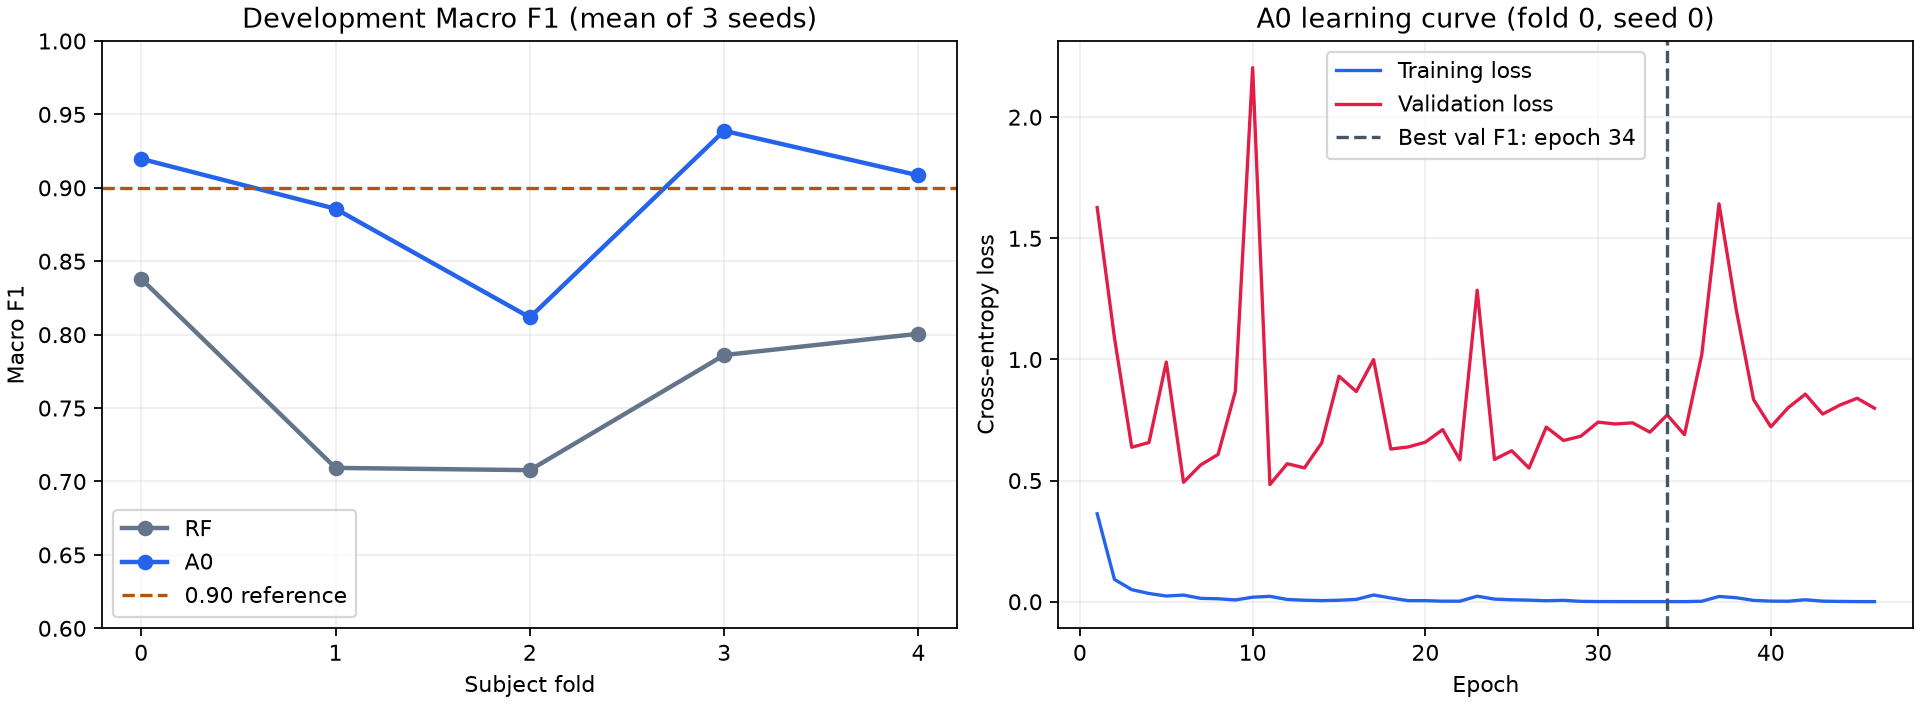

In [1]:
# 학습 완료 후 저장된 결과로 RF와 비교하고 학습 곡선을 확인한다.
import matplotlib.pyplot as plt
rf_runs = pd.read_csv(os.path.join(RUN_DIR, 'RF_runs.csv'))
a0_runs = pd.read_csv(os.path.join(RUN_DIR, 'A0_runs.csv'))
expected = {(f, s) for f in range(5) for s in range(3)}
for frame in [a0_runs, rf_runs]:
    assert len(frame) == 15 and set(zip(frame['fold'], frame['seed'])) == expected
comparison = pd.DataFrame({
    'RF': rf_runs.groupby('fold')['macro_f1'].mean(),
    'A0': a0_runs.groupby('fold')['macro_f1'].mean(),
})
comparison['difference_pp'] = (comparison['A0'] - comparison['RF']) * 100
print(comparison.round(4).to_string())
print('평균 차이(%p):', round(comparison['difference_pp'].mean(), 2))
print('개선 fold:', int((comparison['difference_pp'] > 0).sum()), '/ 5')

history0 = pd.read_csv(os.path.join(RUN_DIR, 'A0_fold0_seed0_history.csv'))
best = int(a0_runs.query('fold == 0 and seed == 0')['best_epoch'].iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
for model_name, color in [('RF', '#64748b'), ('A0', '#2563eb')]:
    axes[0].plot(comparison.index, comparison[model_name], 'o-', label=model_name, color=color, linewidth=2)
axes[0].axhline(0.90, color='#b45309', linestyle='--', label='0.90 reference')
axes[0].set(title='Development Macro F1 (mean of 3 seeds)', xlabel='Subject fold', ylabel='Macro F1', xticks=range(5), ylim=(0.60, 1.0))
axes[0].legend()
epochs = np.arange(1, len(history0) + 1)
axes[1].plot(epochs, history0['loss'], label='Training loss', color='#2563eb')
axes[1].plot(epochs, history0['val_loss'], label='Validation loss', color='#e11d48')
axes[1].axvline(best, color='#475569', linestyle='--', label=f'Best val F1: epoch {best}')
axes[1].set(title='A0 learning curve (fold 0, seed 0)', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()


## 7. 결과 해석 (2026-11-16 정식 결과)

**평가 대상은 개발 30명의 사용자 독립 검증이다. 최종 테스트 6명은 평가하지 않았다.**

| 지표 | A0 | Random Forest 참조선 |
|---|---:|---:|
| Macro F1, fold 평균 ± 표준편차 | **0.8929 ± 0.0493** | 0.7683 ± 0.0578 |
| Accuracy, fold 평균 | **0.9021** | 0.7946 |
| Macro F1 ≥ 0.90인 fold | 3/5 | 0/5 |

- 같은 fold끼리 비교한 Macro F1 차이는 **평균 +12.46%p**, 5개 fold 모두 양수다. 사전 실용 판정 규칙상 RF 대비 개선에 해당한다. 이는 통계적 유의성 검정 결과를 뜻하지 않는다.
- RF는 47개 통계 특징, A0는 원시 시계열을 사용한다. 따라서 **이 두 구현을 비교했을 때 A0가 더 높았다**고 해석한다. 모든 RF보다 CNN이 낫다거나 시간 순서 하나만이 차이를 만들었다고 단정하지 않는다. A0의 검증 점수는 epoch 선택에도 사용했으므로 최종 일반화 성능은 별도 테스트에서 확인해야 한다.
- Accuracy는 0.90을 넘었지만 주 지표인 **Macro F1 평균은 0.90에 미달**했다. 두 지표를 바꿔 쓰지 않는다.
- fold 2의 Macro F1은 0.8117로 가장 낮다. 사용자별 정확도도 30번 0.227, 25번 0.401, 9번 0.448로 낮다. 30번의 Walking은 seed 3개 예측 합산 261개 중 236개가 Jogging으로 분류됐다. 어려운 사람을 제외하지 않고 후속 구조가 이 사람들과 다른 사람들에게 각각 어떤 변화를 주는지 확인한다.
- 사람마다 동일 비중을 준 평균 정확도는 **0.8740**이다. fold 단위 윈도우 정확도 평균 0.9021과 집계 방식이 다르며, 데이터가 많은 사람의 영향도 함께 고려해야 한다.
- fold 0·seed 0 곡선에서는 학습 loss가 낮아져도 검증 loss가 함께 낮아지지 않는다. 저장 가중치는 val loss 최솟값이 아니라 사전에 정한 **검증 Macro F1 최고 epoch** 기준이다. 다른 14회 곡선도 `runs/A0_fold*_seed*_history.csv`에 보존했다.
- 파라미터는 **84,870개**, 15회 학습시간 합계는 **707.6초(약 11.8분)**, 실행당 평균 약 47초다. 데이터 준비·전송 등은 제외한 시간이며 다른 환경과 속도 비교에 사용하지 않는다.

**실행 기록:** Google Colab CLI 0.8.0, T4 GPU, TensorFlow 2.21.0, NumPy 2.4.6. CLI 연결이 한 차례 끊겼지만 원격 학습은 계속됐고, 재연결 후 15개 완료 기록을 읽어 중복 학습 없이 요약 셀을 실행했다. 따라서 학습 셀 출력은 재개 확인 메시지이며, 실제 epoch별 학습 곡선과 최적 가중치·검증 예측은 별도 파일로 보존했다. 위 추가 비교·그림은 회수된 CSV로 PC에서 계산했다.

**다음 실험:** 04의 A1(Residual)을 같은 5 fold·3 seed로 실행해 A0와 비교한다. 특히 fold 2와 사용자 30번의 변화가 다른 사용자 개선과 함께 나타나는지 확인한다. 분할·정제·판정 기준은 유지한다.
